# Analysing a C-GAIMMD run

A C-GAIMMD run leaves behind what every AIMMD run leaves behind (shots, free
simulations, the trainer's networks and its log) and, next to every shot, a
*sidecar* that records how its shooting point was made. This tutorial turns such
a run folder into the results a paper needs, in this order:

1. a run to analyse: two minutes of a C-GAIMMD campaign on a toy system;
2. the shot table and the run progression: which configurations were generated
   at which committor, and where their shots went;
3. rates, from the trainer's reweighting repeated offline, checked against the
   transitions counted in the free simulations;
4. free energies along a pair of collective variables, with the generated
   shooting points on top;
5. how rates and free energies converge with the amount of data;
6. the committor model against brute-force shooting, next to an ordinary
   committor model trained on the same shots;
7. how closely the generator follows the requested committor, and whether its
   samples look like molecular dynamics at that committor;
8. shooting validation: the committor of generated configurations, measured
   by shooting from them;
9. the run card: every setting of the run, as a table.

Why rates and free energies come from AIMMD's reweighting, and not from
estimators that need the probability with which each shooting point was
proposed, is explained on the documentation page *Analysis and estimators*.
That page also lists each analysis with the functions that make it.

Every analysis function used here only reads the run folder. Results are
returned as objects; whatever is saved goes to a folder you choose (here
`analysis/`), and a target inside the run folder is refused.

The notebook runs on a CPU in about four minutes on a workstation, half of them
spent on the run of section 1. **To analyse your own run**, run section 0, set
`PARAMS_FILE` and `RUN` at the end of section 1 to your params file and run
folder, and go on from there. Sections 6 to 8 use the toy system's own dynamics for brute-force
shooting and fresh trajectories; for a molecular system, the same functions
take your brute-force set and your MD frames, as the text says where it
matters.

## 0. Imports, a working folder and the figure style

Everything is created in a fresh temporary folder. The figures use one small
palette: greys for free energies and context, blue and orange for two series,
and a blue-grey-red scale for the committor (blue toward A, red toward B).

In [1]:
import glob
import json
import os
import subprocess
import sys
import tempfile
import warnings

warnings.filterwarnings("ignore", category=UserWarning, module="MDAnalysis")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.formatwarning = lambda message, category, *args, **kwargs: (   # the message only,
    f"{category.__name__}: {message}\n")                               # without the source line

import aimmd
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap

work = tempfile.mkdtemp(prefix="cgaimmd_analysis_")
os.chdir(work)
sys.path.insert(0, work)                  # the toy module written below is imported from here
ANALYSIS = os.path.abspath("analysis")    # where this notebook saves its results
os.makedirs(ANALYSIS)

INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
COMMITTOR = LinearSegmentedColormap.from_list("committor", [BLUE, "#f0efec", "#e34948"])
FES_GREYS = LinearSegmentedColormap.from_list("free_energy", ["#b9b8b0", SURFACE])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": SECONDARY, "ytick.color": SECONDARY, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2, "figure.dpi": 110,
})


def short(path):
    """A path relative to the working folder, for printing."""
    return os.path.relpath(path, work)


print("working in a fresh temporary folder; results go to", short(ANALYSIS))

working in a fresh temporary folder; results go to analysis


## 1. A run to analyse

**The toy system.** One particle moves in a plane by Brownian dynamics in the
*three-hole potential*: two deep wells, one at each of two fixed atoms (the
*sites*, at $x = \pm 1$ Å), and a shallow well between them at
$(0, 1.5)$ Å. A hill at the centre separates the deep wells, so the particle
goes from one to the other along one of two channels: directly, below the
hill, or through the shallow well above it. State A is the particle within
0.4 Å of site 1, state B within 0.4 Å of site 2, and everything else is the
reactive region R. The barrier is about 4.7 kT.

The two sites never move. They are part of every frame so that the system has
distances between atoms, which the baseline committor model of section 6 takes
as its input, as a distance-matrix model does for a molecule. Lengths are in
Å, energies in kT, and times in frames (one frame is ten steps of the
dynamics).

The module `three_hole.py` holds the system and the network:

- `potential`, `force`, `brownian` (the dynamics, for one particle or many at
  once), `state_of`, and the two functions AIMMD's toy engine calls,
  `toy_mdrun` and `states_function`;
- `shoot_one_way` and `trajectories`, the same dynamics for many particles at
  once with numpy; sections 6 and 7 use them for brute-force shooting and for
  fresh MD frames;
- `ParticleNetwork`, the minimal flow-matching network `TinyFlowNetwork` of
  tutorial 3 for the three atoms, with its committor computed from the
  particle's $x$ and $y$.

In [2]:
TOY = '''
"""The toy system of tutorial 7: one particle in the three-hole potential, and two fixed sites."""
import numpy as np
import torch

from aimmd.cgaimmd.flow_matching.toy import TinyFlowNetwork

BETA = 2.0                       # 1 / kT, in units of the potential
DT = 0.005                       # time step of the Brownian dynamics
STEPS_PER_FRAME = 10             # time steps between two saved frames
SITES = np.array([[-1.0, 0.0, 0.0], [1.0, 0.0, 0.0]])   # atoms 1 and 2; they never move
STATE_RADIUS = 0.4               # A (B): the particle within this distance of site 1 (2)


def potential(x, y):
    """The three-hole potential: deep wells at the sites, a shallow one at (0, 1.5)."""
    return (3 * np.exp(-x**2 - (y - 1 / 3)**2) - 3 * np.exp(-x**2 - (y - 5 / 3)**2)
            - 5 * np.exp(-(x - 1)**2 - y**2) - 5 * np.exp(-(x + 1)**2 - y**2)
            + 0.2 * x**4 + 0.2 * (y - 1 / 3)**4)


def force(x, y):
    """Minus the gradient of the potential."""
    e1, e2 = np.exp(-x**2 - (y - 1 / 3)**2), np.exp(-x**2 - (y - 5 / 3)**2)
    e3, e4 = np.exp(-(x - 1)**2 - y**2), np.exp(-(x + 1)**2 - y**2)
    fx = 6 * x * e1 - 6 * x * e2 - 10 * (x - 1) * e3 - 10 * (x + 1) * e4 - 0.8 * x**3
    fy = (6 * (y - 1 / 3) * e1 - 6 * (y - 5 / 3) * e2 - 10 * y * e3 - 10 * y * e4
          - 0.8 * (y - 1 / 3)**3)
    return fx, fy


def brownian(x, y, n_steps, rng=np.random):
    """`n_steps` steps of overdamped Langevin dynamics, for one particle or many at once."""
    width = np.sqrt(2 * DT / BETA)
    for _ in range(n_steps):
        fx, fy = force(x, y)
        x = x + DT * fx + width * rng.normal(size=np.shape(x))
        y = y + DT * fy + width * rng.normal(size=np.shape(y))
    return x, y


def state_of(x, y):
    """'A' near site 1, 'B' near site 2, 'R' anywhere else."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    labels = np.full(x.shape, 'R', dtype='<U1')
    labels[(x - SITES[0, 0])**2 + (y - SITES[0, 1])**2 < STATE_RADIUS**2] = 'A'
    labels[(x - SITES[1, 0])**2 + (y - SITES[1, 1])**2 < STATE_RADIUS**2] = 'B'
    return labels


def toy_mdrun(ts):
    """AIMMD's toy engine: advance the particle by one frame (the sites stay where they are)."""
    positions = ts.positions
    positions[0, :2] = brownian(float(positions[0, 0]), float(positions[0, 1]), STEPS_PER_FRAME)
    ts.positions = positions


def states_function(trajectory):
    # copy each row: the reader reuses one array for every frame
    xy = np.array([frame.positions[0, :2].copy() for frame in trajectory]).reshape(-1, 2)
    return state_of(xy[:, 0], xy[:, 1])


def shoot_one_way(x, y, n_shots, rng, max_frames=5000):
    """Brute-force shooting: `n_shots` trajectories from each point (x, y), each run until A or B.

    Returns the counts (n_A, n_B) per point. Brownian dynamics have no velocities, so trajectories
    started from a point play the role that two-way shots with fresh velocities play in MD.
    """
    x = np.repeat(np.asarray(x, dtype=float), n_shots)
    y = np.repeat(np.asarray(y, dtype=float), n_shots)
    ends = np.full(len(x), 'R', dtype='<U1')
    running = np.arange(len(x))
    for _ in range(max_frames):
        if not len(running):
            break
        x[running], y[running] = brownian(x[running], y[running], STEPS_PER_FRAME, rng)
        ends[running] = state_of(x[running], y[running])
        running = running[ends[running] == 'R']
    ends = ends.reshape(-1, n_shots)
    return (ends == 'A').sum(axis=1), (ends == 'B').sum(axis=1)


def trajectories(x, y, n_frames, rng):
    """`n_frames` frames of the dynamics from each point (x, y): an array (n_frames, n_points, 2)."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    frames = []
    for _ in range(n_frames):
        x, y = brownian(x, y, STEPS_PER_FRAME, rng)
        frames.append(np.stack([x, y], axis=-1))
    return np.array(frames)


class ParticleNetwork(TinyFlowNetwork):
    """TinyFlowNetwork for the three atoms, with its committor computed from the particle's x and y."""

    def __init__(self):
        super().__init__(n_atoms=3, hidden=64, prior_center=0.0, prior_width=1.0,
                         lambda_clip=10.0)
        self.committor_net = torch.nn.Sequential(
            torch.nn.Linear(2, 32), torch.nn.SiLU(), torch.nn.Linear(32, 32), torch.nn.SiLU(),
            torch.nn.Linear(32, 1))
        torch.nn.init.zeros_(self.committor_net[-1].weight)    # untrained: lambda = 0 everywhere
        torch.nn.init.zeros_(self.committor_net[-1].bias)

    def forward(self, inp):
        x = torch.flatten(torch.as_tensor(inp, dtype=torch.float32), start_dim=1)
        return self.committor_net(x[:, :2])
'''
with open("three_hole.py", "w") as handle:
    handle.write(TOY.lstrip())
import three_hole

print("wrote three_hole.py")

wrote three_hole.py


The params file is a C-GAIMMD params file like the one of tutorial 3, with
settings for a short run:

- the generator generates all three atoms; the preparation hook
  (`cgaimmd_prepare_function`) then puts the two sites back in place and the
  particle in the plane, the job that re-solvation and minimisation do for a
  molecule;
- the target committors $\lambda^*$ are drawn uniformly in $[-3, 3]$; after
  30 trained shooting points the final check accepts a candidate only if its
  committor $\lambda$ is within 1 of the target;
- the free simulations restart from the equilibrium inside their state
  (`free_restart_source = 'equilibrium'`), so their transitions give a rate of
  their own (section 3);
- each training round runs 1,500 steps of the flow-matching fit, starting
  again from `initial_network`, with a larger learning rate than the default
  and no warm-up; the network the shooting workers use is a running average of
  the weights over about the last 100 steps (`ema_decay=0.99`; the default,
  0.999, averages over about 1,000 steps, which suits the default rounds of
  4,000 steps but would here still carry much of the untrained start).

In [3]:
PARAMS = '''
"""C-GAIMMD on the three-hole toy system (tutorial 7)."""
import numpy as np

from aimmd.cgaimmd.flow_matching.fit import flow_matching_fit
from aimmd.cgaimmd.preparation.descriptors import coordinates_descriptors
from aimmd.cgaimmd.types import PreparedFrame, ValidityResult

from three_hole import SITES, ParticleNetwork, states_function, toy_mdrun

engine = 'toy'
toy_slowdown = 0.0005                     # seconds between frames (the default, 0.01, is for watching)
chain_type = 'cgaimmd'
states = 'ARB'
initial_paths = ['initial_A.xtc', 'initial_B.xtc']   # end-state frames, one file per state
initial_network = 'initial_network.h5'
round_shooting_index = True
masses_from_topology = True
free_restart_source = 'equilibrium'

cgaimmd_generator = {'method': 'ode', 'sampler': 'midpoint', 'n_steps': 16, 'chunk': 64}
cgaimmd_parameters = {
    'lambda_window': (-3.0, 3.0),
    'window_after_trained_shots': 30,
    'n_targets': 16,
    'max_refills': 5,
    'wait_seconds': 1.0,
    'generation_seed': 0,
    'generation_device': 'cpu',
    'values_device': 'cpu',
    'training_device': 'cpu',
}


def descriptors_function(trajectory):
    return coordinates_descriptors(trajectory)        # (n_frames, 9): x, y, z of the three atoms


class Network(ParticleNetwork):
    pass


network = Network()


def cgaimmd_validity_function(positions, context):
    """Keep the samples whose particle lies in the region the potential confines it to."""
    x, y = positions[:, 0, 0], positions[:, 0, 1]
    ok = (np.abs(x) <= 2.0) & (y >= -1.5) & (y <= 2.5)
    reason = np.array(['' if keep else 'outside_region' for keep in ok], dtype=object)
    return ValidityResult(positions=positions, ok=ok, reason=reason)


def cgaimmd_prepare_function(positions, context):
    """Put the two sites back in place and the particle in the plane."""
    frame = np.array(positions, dtype=float)
    frame[0, 2] = 0.0
    frame[1:] = SITES
    return PreparedFrame(positions=frame, dimensions=None, record={'sites': 'put back'})


def fit(params, pathensemble, verbose=False, worker=None):
    return flow_matching_fit(params, pathensemble, verbose=verbose, worker=worker,
                             steps_per_round=1500, relabel_every=500, lr=3e-3,
                             warmup_steps=0, ema_decay=0.99)
'''
with open("params.py", "w") as handle:
    handle.write(PARAMS.lstrip())
print("wrote params.py")

wrote params.py


**The run.** Ten end-state frames per state and an untrained initial
network, then the Launcher runs four shooting chains, one free simulation in
each state and the trainer, all at once, for two minutes. It runs in a process
of its own, so that its messages and those of its workers go to `launcher.log`;
every worker also writes its own log into the run folder. At the end of the two
minutes every worker is stopped wherever it is, as in a production run whose
job ends.

In [4]:
import MDAnalysis as mda

universe = mda.Universe.empty(3, trajectory=True)
for state, site in (("A", three_hole.SITES[0]), ("B", three_hole.SITES[1])):
    with mda.Writer(f"initial_{state}.xtc", 3) as writer:
        for i in range(10):
            particle = site + [0.05 * np.sin(i), 0.05 * np.cos(i), 0.0]
            universe.atoms.positions = np.vstack([particle, three_hole.SITES])
            writer.write(universe.atoms)
torch.manual_seed(0)
torch.save(three_hole.ParticleNetwork().state_dict(), "initial_network.h5")

LAUNCH = "import aimmd; aimmd.Launcher('params.py', 'run').run(4, 1, 1, walltime=120)"
with open("launcher.log", "w") as log:
    subprocess.run([sys.executable, "-c", LAUNCH], stdout=log, stderr=subprocess.STDOUT, check=True)

PARAMS_FILE = "params.py"            # to analyse your own run: its params file ...
RUN = os.path.abspath("run")         # ... and its run folder

n_shots = len(glob.glob(f"{RUN}/chainR*/path??????.xtc"))
n_free = {s: len(glob.glob(f"{RUN}/free{s}/traj*.xtc")) for s in "AB"}
round_info = json.load(open(f"{RUN}/networkARB.json"))
print(f"{n_shots} shots in 4 chains; free-simulation files: {n_free}; "
      f"the last network the trainer completed: round {round_info['round']}, "
      f"trained on {round_info['n_trained_shots']} shots")

184 shots in 4 chains; free-simulation files: {'A': 30, 'B': 24}; the last network the trainer completed: round 6, trained on 73 shots


In [5]:
params = aimmd.Params.load(PARAMS_FILE, save=False)
print("states", params.states, "| chain type", params.chain_type,
      "| generator", params.cgaimmd_generator)

C-GAIMMD: initial path 'initial_A.xtc' has no 'ARB' transition; it seeds free simulations only
C-GAIMMD: initial path 'initial_B.xtc' has no 'ARB' transition; it seeds free simulations only
states ARB | chain type cgaimmd | generator {'method': 'ode', 'sampler': 'midpoint', 'n_steps': 16, 'chunk': 64}


## 2. The shot table and the run progression

`shot_table` reads the sidecars and the state caches of a run and returns one
row per shot, in the order the shots were registered:

- `chain`, `path`: where the shot is;
- `first_state`, `last_state`: where its two halves ended (a registered path
  holds the backward half reversed, then the forward half, so `first_state`
  is the end of the backward half); `reactive` is True when they differ;
- `lambda_target`: the requested committor $\lambda^*$, a logit;
- `lambda_final`: the committor $\lambda$ the network gave the frame that was
  shot, measured on the prepared frame;
- `acceptance_rule`: `'bootstrap_any_R'` while the network had not yet been
  trained on enough shooting points (any frame in R was accepted), then
  `'target'` (accepted only if $|\lambda - \lambda^*| \le 1$);
- the network round, the candidates tried and rejected (by reason), and the
  time spent on each stage.

`cv=` adds collective variables of each shooting point. Here they are $x$ and
$y$ of the particle, columns 0 and 1 of the descriptor cache; reading a cache
(`cv_source='descriptors'`) is much faster than opening the trajectories. A
callable that gets a trajectory reader (the default `cv_source`) works for any
other quantity. `summarise_shots` counts the rows.

In [6]:
from aimmd.cgaimmd.sidecar import shot_table, summarise_shots

XY = {"x": lambda rows: rows[:, 0], "y": lambda rows: rows[:, 1]}   # columns 0, 1: the particle
rows = shot_table(RUN, params=params, cv=XY, cv_source="descriptors")
summary = summarise_shots(rows)

print(f"{'shot':>4s}  {'chain':7s} {'path':15s} {'ends':4s} {'rule':15s} {'lambda*':>7s} "
      f"{'lambda':>7s} {'x':>6s} {'y':>6s}")
for row in rows[:3] + rows[-3:]:
    print(f"{row['shot_index']:4d}  {row['chain']:7s} {row['path']:15s} "
          f"{row['first_state']}{row['last_state']:3s} {row['acceptance_rule']:15s} "
          f"{row['lambda_target']:+7.2f} {row['lambda_final']:+7.2f} {row['x']:+6.2f} {row['y']:+6.2f}")
print()
for key in ("n_shots", "n_reactive", "path_types", "acceptance_rules", "candidates_rejected"):
    print(f"{key:20s} {summary[key]}")

shot  chain   path            ends rule            lambda*  lambda      x      y
   0  chainR0 path000001.xtc  AB   bootstrap_any_R   -0.37   +0.00  +0.07  +1.96
   1  chainR2 path000001.xtc  AA   bootstrap_any_R   +0.64   +0.00  -1.42  +2.45
   2  chainR0 path000002.xtc  AA   bootstrap_any_R   -0.64   +0.00  -0.23  -0.29
 181  chainR2 path000041.xtc  AA   target            -1.77   -2.35  -1.10  +0.62
 182  chainR3 path000045.xtc  AA   target            -1.57   -2.06  -1.00  +0.69
 183  chainR1 path000048.xtc  BB   target            -0.04   +0.35  +0.14  -0.18

n_shots              184
n_reactive           47
path_types           {'AA': 73, 'AB': 24, 'BA': 23, 'BB': 64}
acceptance_rules     {'bootstrap_any_R': 68, 'target': 116}
candidates_rejected  {'lambda_window': 60, 'state_A': 35, 'state_B': 22}


The rejections are those of the final check: `lambda_window` is a prepared
candidate whose committor was more than 1 away from its target, `state_A` and
`state_B` a candidate that landed in a state.

**The run progression.** Every shot in registration order: what it was asked
for ($\lambda^*$, open circles), the committor of the frame that was shot
($\lambda$, filled), and where its halves went (colour). Under the bootstrap
rule the untrained network gives every frame $\lambda = 0$, and the frames are
wherever the untrained generator put them. Once the final check is enforced,
the filled circles follow the requests. The lower panel counts the
transitions.

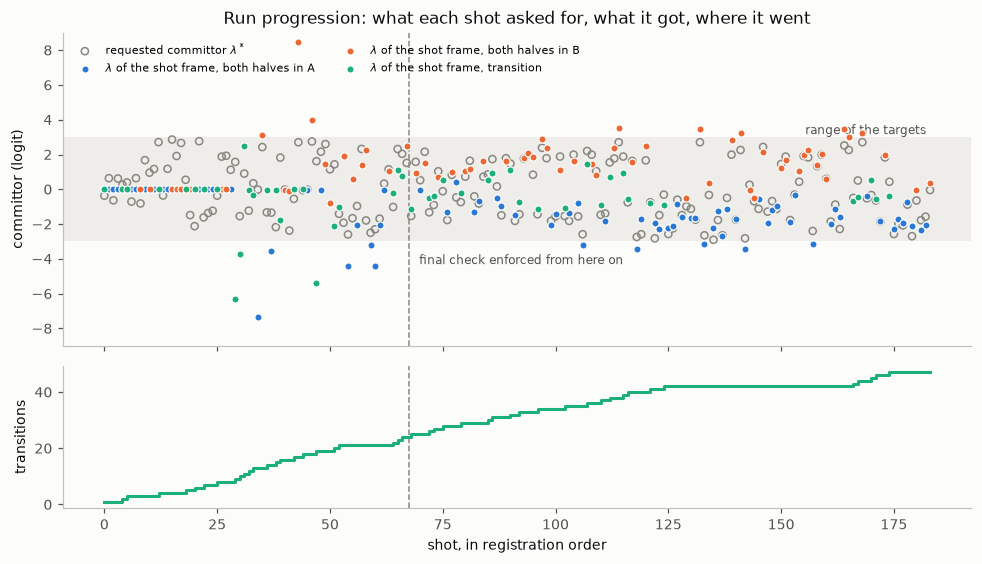

In [7]:
index = np.array([row["shot_index"] for row in rows])
target = np.array([row["lambda_target"] for row in rows])
final = np.array([row["lambda_final"] for row in rows])
ends = np.array([row["first_state"] + row["last_state"] for row in rows])
enforced = np.array([bool(row["acceptance_enforced"]) for row in rows])
outcome = np.where(ends == "AA", "both halves in A",
                   np.where(ends == "BB", "both halves in B", "transition"))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True,
                                  gridspec_kw={"height_ratios": [2.2, 1]})
top.axhspan(-3, 3, color=GRID, alpha=0.5, linewidth=0)
top.text(index.max(), 3, "range of the targets ", color=SECONDARY, fontsize=8, ha="right",
         va="bottom")
if enforced.any():
    first = index[enforced].min()
    for ax in (top, bottom):
        ax.axvline(first - 0.5, color=MUTED, linewidth=1, linestyle="--")
    top.text(first, -4.1, "  final check enforced from here on", color=SECONDARY, fontsize=8,
             va="center")
top.scatter(index, target, s=22, facecolor="none", edgecolor=MUTED, linewidth=1,
            label=r"requested committor $\lambda^*$")
for label, color in (("both halves in A", BLUE), ("both halves in B", ORANGE),
                     ("transition", AQUA)):
    mask = outcome == label
    top.scatter(index[mask], final[mask], s=22, color=color, edgecolor=SURFACE, linewidth=0.8,
                label=rf"$\lambda$ of the shot frame, {label}", zorder=3)
limit = max(4.5, np.abs(np.r_[target, final]).max() + 0.5)
top.set_ylim(-limit, limit)
top.set_ylabel("committor (logit)")
top.legend(loc="upper left", ncol=2, fontsize=7.5)
top.set_title("Run progression: what each shot asked for, what it got, where it went")
bottom.plot(index, summary["cumulative_reactive"], color=AQUA, drawstyle="steps-post")
bottom.set_ylabel("transitions")
bottom.set_xlabel("shot, in registration order")
fig.tight_layout()
plt.show()

## 3. Rates

The rate $k_{AB}$ is the number of transitions from A to B per unit of time
spent with A as the last state visited; $1/k_{AB}$ is the mean time to go from
A to B. AIMMD's trainer estimates both rates after every round by reweighting
the path ensemble: the shots and the free-simulation excursions are ordered
by the committor values of their frames, the probability that an excursion
leaving a state climbs from one committor level to the next is estimated
level by level, and every path is weighted so that the ensemble has these
crossing probabilities. The rates follow from the weighted time spent with
each state as the last one visited. The unit here is one per frame.

`reweight_run` repeats that reweighting offline by calling AIMMD's own code.
With the committor values stored in the run (`values='cached'`, the default),
it computes what the trainer computed. `trainer_rate_estimates` reads every
estimate the trainer printed, with the round and the number of shots it had.

In [8]:
from aimmd.analysis.reweighting import reweight_run, trainer_rate_estimates

printed = trainer_rate_estimates(f"{RUN}/trainARB.log")
cached = reweight_run(params, RUN)

print(f"the trainer's last estimate (round {printed['round'][-1]}, "
      f"{printed['n_shots'][-1]} shots): k_AB = {printed['k12'][-1]:.3e}, "
      f"k_BA = {printed['k21'][-1]:.3e} per frame")
print(f"reweight_run, cached values ({cached.n_shots} shots): "
      f"k_AB = {cached.k12:.3e}, k_BA = {cached.k21:.3e} per frame")
print("left out because their frames have no stored value yet:",
      {key: len(value) for key, value in cached.left_out.items()})

the trainer's last estimate (round 6, 116 shots): k_AB = 8.007e-04, k_BA = 8.044e-04 per frame
reweight_run, cached values (127 shots): k_AB = 9.939e-04, k_BA = 8.878e-04 per frame
left out because their frames have no stored value yet: {'free_frames': 9, 'shots': 57}


Two things to read in this output.

- **The trainer's last estimate is older than the run.** The workers kept
  shooting after the trainer's last estimate; `reweight_run` counts the shots
  whose frames already have stored values and leaves out those registered
  after the last value pass (a frame without a value would read as a logit of
  0, a committor of one half). On a run folder that holds exactly the data of
  the trainer's last estimate, the two agree to the last digit.
- **The warning about frames without a known state.** When the run was
  stopped, the free simulations had written frames that their workers had not
  yet labelled with a state. The trainer counts such frames like any other,
  and `reweight_run` does the same so that it reproduces the trainer. Here they
  are a few percent of the frames; check this number before you quote rates of
  a run of your own.

For the numbers to report, every frame should be scored by one network:
`values='recompute'` computes the committor of every reactive frame again, in
memory, with the run's last network (`networkARB.h5`, or any network file you
pass). `fractions=` repeats the reweighting on the first 20 %, 40 %, ... of the
data (section 5).

The free simulations give a second estimate that needs no committor at all:
`free_md_rates` counts their transitions and the time they spent on each side,
with exact Poisson 95 % intervals. It is only valid when each free simulation
restarts from the equilibrium inside its state, which is why the params set
`free_restart_source = 'equilibrium'` (the function warns otherwise). Few
transitions make for a wide interval; the reweighted rates should fall inside
it. The potential is symmetric, so the exact $k_{AB}$ and $k_{BA}$ are equal:
the difference between the two estimates shows the statistical error of a
two-minute run.

In [9]:
from aimmd.analysis.free_md import free_md_rates

rates = reweight_run(params, RUN, values="recompute", fractions=(0.2, 0.4, 0.6, 0.8),
                     fraction_by="time")
counted = free_md_rates(params, RUN)

print(f"values recomputed with {short(rates.network)}: {rates.n_shots} shots, "
      f"{rates.free_frames} free-simulation frames")
for name, k, direction in (("k_AB", rates.k12, "AB"), ("k_BA", rates.k21, "BA")):
    free = counted[direction]
    print(f"  {name}: reweighted {k:.2e} per frame | free simulations alone {free['rate']:.2e} "
          f"[{free['lower']:.2e}, {free['upper']:.2e}] from {free['transitions']} transitions "
          f"in {free['frames']} frames")

values recomputed with run/networkARB.h5: 184 shots, 33434 free-simulation frames
  k_AB: reweighted 7.61e-04 per frame | free simulations alone 8.53e-04 [4.66e-04, 1.43e-03] from 14 transitions in 16420 frames
  k_BA: reweighted 7.70e-04 per frame | free simulations alone 6.61e-04 [3.30e-04, 1.18e-03] from 11 transitions in 16649 frames


The reweighting also gives every frame an *equilibrium weight*: how much that
frame counts when the ensemble stands in for one long equilibrium trajectory.
Summed by region they give the populations; summed by the last state visited
they give the history populations, whose ratio equals $k_{BA}/k_{AB}$ in a
two-state system. `save` writes the scalar results (JSON) and the per-path
arrays (npz); a target inside the run folder is refused.

In [10]:
shares = rates.populations()
print("share of the equilibrium weight per region:   ",
      {key: round(value, 3) for key, value in shares["state"].items()})
print("share by the last end state visited (history):",
      {key: round(value, 3) for key, value in shares["last_visited"].items()})
print(f"P(last A) / P(last B) = {shares['last_visited']['A'] / shares['last_visited']['B']:.2f}"
      f";  k_BA / k_AB = {rates.k21 / rates.k12:.2f}")
rates.save(os.path.join(ANALYSIS, "rates"))
print("saved:", sorted(os.listdir(ANALYSIS)))

share of the equilibrium weight per region:    {'A': 0.353, 'R': 0.298, 'B': 0.349}
share by the last end state visited (history): {'A': 0.503, 'B': 0.497, 'none': 0.0}
P(last A) / P(last B) = 1.01;  k_BA / k_AB = 1.01
saved: ['rates.json', 'rates.npz']


## 4. Free energies and the generated shooting points

`frame_table` lists every frame the rates count, with its equilibrium weight,
its state, the last state it visited, its committor value and any collective
variables; `free_energy` turns the weighted frames into
$F = -\ln p$ in units of kT on a grid, with the lowest bin at 0. Under a
static bias (`record_bias`) the weights include $e^{\text{bias}}$, so that
$F$ describes the unbiased system.

For the toy the exact answer is known: Brownian dynamics sample the Boltzmann
distribution, so $F(x, y) = V(x, y)/kT$ up to a constant.
`free_energy_difference` measures how far a surface is from a reference on the
same grid: the root-mean-square difference over the bins where both have data,
weighted by the reference probability, after the best constant shift
(free energies are defined only up to a constant), and the share of the
reference probability that the estimate covers.

In [11]:
from aimmd.analysis.reweighting import (FreeEnergy, frame_table, free_energy,
                                        free_energy_difference)

GRID_RANGE = [(-2.0, 2.0), (-1.5, 2.5)]
table = frame_table(rates, cv=XY, cv_source="descriptors")
fes = free_energy(table, bins=32, range=GRID_RANGE)

# the toy's exact free energy on the same grid
cx, cy = np.meshgrid(*fes.centers, indexing="ij")
exact_f = three_hole.BETA * three_hole.potential(cx, cy)
exact_p = np.exp(-exact_f) / np.exp(-exact_f).sum()
exact = FreeEnergy(free_energy=exact_f - exact_f.min(), probability=exact_p,
                   n_frames=np.ones_like(exact_p), edges=fes.edges, names=fes.names)

print(f"{len(table.weight)} weighted frames; free energy on a "
      f"{fes.free_energy.shape[0]} x {fes.free_energy.shape[1]} grid")
print("against the exact free energy:",
      {key: round(value, 3) for key, value in free_energy_difference(fes, exact).items()})

37876 weighted frames; free energy on a 32 x 32 grid
against the exact free energy: {'rms': 0.141, 'shift': 0.031, 'coverage': 0.999}


**The generated shooting points on the free energy** (a figure of the kind a
paper shows for each system): the free-energy surface of the run in grey with
contours every 1 kT, and the shooting points as circles. The shots taken
under the final check are coloured by the committor $p_B = 1/(1 + e^{-\lambda})$
of the run's last network; the bootstrap shots, taken before the generator had
learned anything, are small grey circles. The run was given no transition, only
end-state frames, and the generated points still cover both channels.

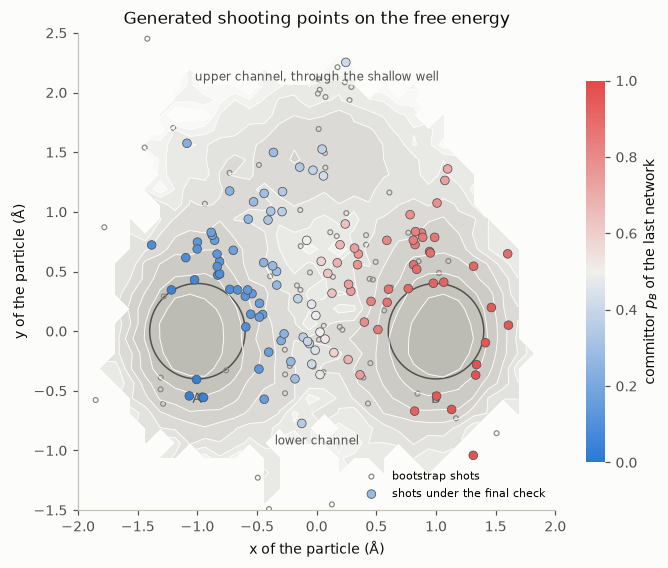

In [12]:
network = params.network
network.load_state_dict(torch.load(f"{RUN}/networkARB.h5", weights_only=True))
network.eval()
points = np.array([[row["x"], row["y"]] for row in rows])
with torch.no_grad():
    frames = np.hstack([points, np.zeros((len(points), 1)),
                        np.tile(three_hole.SITES.ravel(), (len(points), 1))])
    p_b = torch.sigmoid(network(torch.as_tensor(frames))).numpy().ravel()

fig, ax = plt.subplots(figsize=(6.4, 5.2))
f_plot = np.where(np.isfinite(fes.free_energy), fes.free_energy, np.nan).T
contour_levels = np.arange(0, 10, 1.0)
ax.contourf(*fes.centers, f_plot, levels=contour_levels, cmap=FES_GREYS, extend="max")
ax.contour(*fes.centers, f_plot, levels=contour_levels, colors=SURFACE, linewidths=0.6)
for site, label in zip(three_hole.SITES, "AB"):
    ax.add_patch(plt.Circle(site[:2], three_hole.STATE_RADIUS, fill=False, color=SECONDARY,
                            linewidth=1))
    ax.text(site[0], site[1] - 0.6, label, ha="center", color=SECONDARY)
ax.scatter(*points[~enforced].T, s=10, facecolor="none", edgecolor=MUTED, linewidth=0.8,
           label="bootstrap shots")
shown = ax.scatter(*points[enforced].T, c=p_b[enforced], cmap=COMMITTOR, vmin=0, vmax=1, s=32,
                   edgecolor=SECONDARY, linewidth=0.5, zorder=3,
                   label="shots under the final check")
colorbar = fig.colorbar(shown, ax=ax, shrink=0.8)
colorbar.set_label("committor $p_B$ of the last network")
colorbar.outline.set_visible(False)
ax.text(0, 2.1, "upper channel, through the shallow well", ha="center", color=SECONDARY,
        fontsize=8)
ax.text(0, -0.95, "lower channel", ha="center", color=SECONDARY, fontsize=8)
ax.set_xlim(*GRID_RANGE[0])
ax.set_ylim(*GRID_RANGE[1])
ax.set_aspect("equal")
ax.set_xlabel("x of the particle (Å)")
ax.set_ylabel("y of the particle (Å)")
ax.legend(loc="lower right", fontsize=7.5)
ax.set_title("Generated shooting points on the free energy")
fig.tight_layout()
plt.show()

## 5. Convergence of rates and free energies

How much would the results still move with more data? The reweighting of
section 3 was repeated on the first 20 %, 40 %, 60 % and 80 % of the data
(`fractions=`): the shots registered in the first part of the run's time
(`fraction_by='time'`; `'shots'` counts shots instead) and the same share of
every free simulation, all scored by the same last network. This is not a
re-run of the training, which `aimmd.Worker.kinetics_convergence` does.
`free_energy_convergence` computes the free energy of every part on the grid of
all data and its distance to the full-data surface. For the toy the distance
to the exact surface is shown as well; for a real system the distance to all
data is what you have.

In [13]:
from aimmd.analysis.reweighting import free_energy_convergence

convergence = rates.convergence()
fes_parts = free_energy_convergence(rates, XY, cv_source="descriptors", bins=32,
                                    range=GRID_RANGE)
parts = fes_parts["subsets"] + [{"fraction": 1.0, "free_energy": fes_parts["full"],
                                 "difference": {"rms": 0.0}}]
to_exact = [free_energy_difference(part["free_energy"], exact)["rms"] for part in parts]
print(f"{'part':>5s} {'shots':>6s} {'free frames':>11s} {'k_AB':>9s} {'k_BA':>9s} "
      f"{'F: rms to all data':>19s} {'F: rms to exact':>16s}")
for row, part, rms_exact in zip(convergence, parts, to_exact):
    print(f"{row['fraction']:5.1f} {row['n_shots']:6d} {row['free_frames']:11d} "
          f"{row['k12']:9.2e} {row['k21']:9.2e} {part['difference']['rms']:19.2f} "
          f"{rms_exact:16.2f}")

 part  shots free frames      k_AB      k_BA  F: rms to all data  F: rms to exact
  0.2     34        6686  1.15e-03  1.33e-03                0.26             0.26
  0.4     71       13372  9.96e-04  1.01e-03                0.17             0.19
  0.6    104       20060  8.63e-04  8.47e-04                0.12             0.17
  0.8    144       26748  8.79e-04  8.48e-04                0.08             0.15
  1.0    184       33434  7.61e-04  7.70e-04                0.00             0.14


The kinetics convergence figure: the rates of the parts against the number of
shots they hold (blue), the trainer's own estimates during the run (orange,
each with the network of its round; the first ones, from a handful of shots,
can lie outside the plotted range), and the estimate of the free simulations
alone with its 95 % interval (grey line and band). The right panel shows the
free energy.

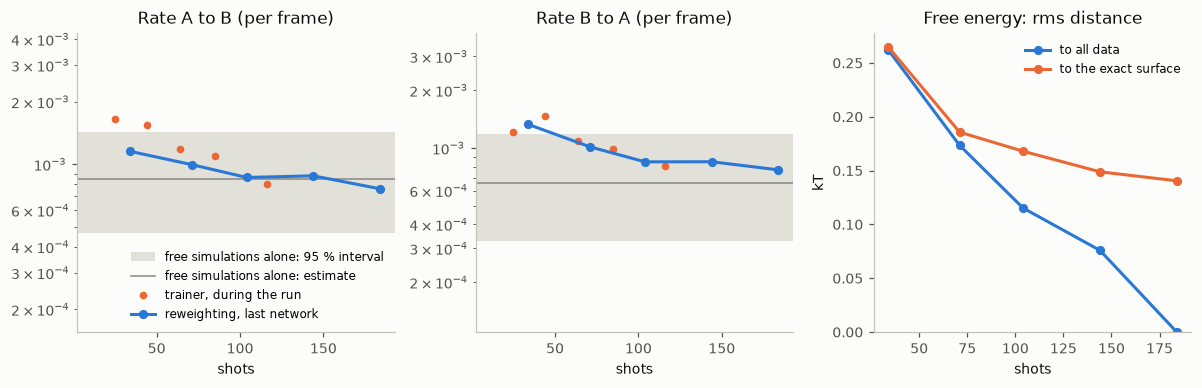

In [14]:
shots = np.array([row["n_shots"] for row in convergence])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, key, direction, title in ((axes[0], "k12", "AB", "A to B"),
                                  (axes[1], "k21", "BA", "B to A")):
    free = counted[direction]
    reweighted = [row[key] for row in convergence]
    ax.axhspan(free["lower"], free["upper"], color=GRID, linewidth=0,
               label="free simulations alone: 95 % interval")
    ax.axhline(free["rate"], color=MUTED, linewidth=1, label="free simulations alone: estimate")
    ax.plot(printed["n_shots"], printed[key], "o", color=ORANGE, markersize=4,
            label="trainer, during the run")
    ax.plot(shots, reweighted, "o-", color=BLUE, markersize=5, label="reweighting, last network")
    ax.set_yscale("log")
    ax.set_ylim(min(free["lower"], min(reweighted)) / 3, max(free["upper"], max(reweighted)) * 3)
    ax.set_xlabel("shots")
    ax.set_title(f"Rate {title} (per frame)")
axes[0].legend(loc="lower right")
axes[2].plot(shots, [part["difference"]["rms"] for part in parts], "o-", color=BLUE,
             markersize=5, label="to all data")
axes[2].plot(shots, to_exact, "o-", color=ORANGE, markersize=5, label="to the exact surface")
axes[2].set_ylim(bottom=0)
axes[2].set_xlabel("shots")
axes[2].set_ylabel("kT")
axes[2].legend(loc="upper right")
axes[2].set_title("Free energy: rms distance")
fig.tight_layout()
plt.show()

## 6. The committor against brute-force shooting, with a baseline

A committor model is judged against a *brute-force set*: configurations whose
committor has been measured by shooting many trajectories from each of them.
For a molecular system this set is computed once, by an AIMMD sweep
(`chain_type='rfps'` with the configurations as initial paths and
`reactive_region_mode='sweep'`, as section 8 runs one) and read with
`validate.sweep_reference`, or loaded from arrays with
`CommittorReference.from_npz` and `CommittorReference.from_trajectory`. For
the toy the shooting is cheap: 400 reactive frames of the run are screened with
32 trajectories each, 8 frames are chosen in every tenth of the screened
committor, and each chosen frame gets 200 fresh trajectories.

In [15]:
from aimmd.cgaimmd.analysis import committor_baseline, validate

rng = np.random.default_rng(7)
candidates = rng.choice(np.flatnonzero(table.state == "R"), 400, replace=False)
xy = table.cv[candidates]
n_a, n_b = three_hole.shoot_one_way(xy[:, 0], xy[:, 1], 32, rng)          # the screening
screened = n_b / (n_a + n_b)
chosen = np.concatenate([rng.permutation(np.flatnonzero((screened >= lo) & (screened <= hi)))[:8]
                         for lo, hi in zip(np.linspace(0, 0.9, 10), np.linspace(0.1, 1, 10))])
xy = xy[chosen]
n_a, n_b = three_hole.shoot_one_way(xy[:, 0], xy[:, 1], 200, rng)       # the reference counts
positions = np.zeros((len(xy), 3, 3))
positions[:, 0, :2] = xy
positions[:, 1:] = three_hole.SITES
reference = validate.CommittorReference.from_arrays("brute force, 200 trajectories", positions,
                                                    n_a, n_b)
print(f"{len(xy)} configurations; how many in each tenth of the brute-force committor:",
      np.histogram(n_b / (n_a + n_b), bins=10, range=(0, 1))[0])

74 configurations; how many in each tenth of the brute-force committor: [10  1  6  5 15  9  8  4  6 10]


**The baseline**: an ordinary AIMMD committor model trained on the same run, so
that the comparison shows what the generative part costs or gains in committor
accuracy. `DistanceMLP` reads the distances between selected atoms (for a
molecule, its heavy atoms; for a protein with a ligand, the pocket and the
ligand), each shifted and scaled by its mean and spread over the run's free
simulations (`run_distance_scaler`). `train_on_run` trains it with AIMMD's own
fit on the run's shots and free simulations (`augment='yes'` adds the
free-simulation segments to the training data), after the run and without
writing into the run folder. Runs with a recorded bias are refused unless you
pass `allow_biased_frames=True`.

In [16]:
import contextlib
import io

selected = [0, 1, 2]                 # the atoms whose distances the baseline reads: all three here
scaler = committor_baseline.run_distance_scaler(params, RUN, selected)
baseline = committor_baseline.DistanceMLP(selected, n_atoms=3, hidden=(32, 32),
                                          mean=scaler["mean"], std=scaler["std"])
torch.manual_seed(0)
with contextlib.redirect_stdout(io.StringIO()):            # AIMMD's fit reports as it goes
    training = committor_baseline.train_on_run(params, RUN, baseline, epochs=2000, lr=1e-3,
                                               augment="yes")
torch.save(baseline.state_dict(), os.path.join(ANALYSIS, "distance_mlp.pt"))
print(f"distance MLP trained on {training['n_shots']} shots and "
      f"{training['n_free_trajectories']} free trajectories; "
      f"loss {training['losses'][0]:.3f} -> {training['losses'][-1]:.3f}")

distance MLP trained on 184 shots and 27 free trajectories; loss 0.694 -> 0.242


`network_committor` turns either network into a function of configurations;
`score_committor` compares it with the counts of the reference. The numbers:

- **log-likelihood per endpoint**: the mean log-probability the model gives
  the observed end of each brute-force trajectory. Higher is better; a model
  that predicts the overall share of B everywhere scores the *constant*
  value, and the exact committor would score about the *estimated ceiling*.
- **calibration slope**: the slope $b$ of the best fit
  $q = \sigma(a + b\lambda)$ of the observed committor $q$ on the model's
  logit. 1 is calibrated; above 1 the model is too cautious (its committors are
  too close to one half), below 1 too confident.
- **Spearman**: the rank correlation of model and brute force: does the model
  order the configurations right?
- **R²** of the committor values, next to its *noise ceiling*: with a finite
  number of trajectories per configuration even the exact committor does not
  reach R² = 1.

`parity_figure` draws the side-by-side parity plots, with these numbers written
in, and saves them as PNG and PDF.

                             log-lik/endpoint  calibration slope  Spearman     R2  R2 noise ceiling
C-GAIMMD model (last round)            -0.506               1.33      0.96   0.88              0.99
distance MLP, same run                 -0.483               0.94      0.98   0.94              0.99
constant model -0.692, exact committor (estimated ceiling) -0.474 per endpoint


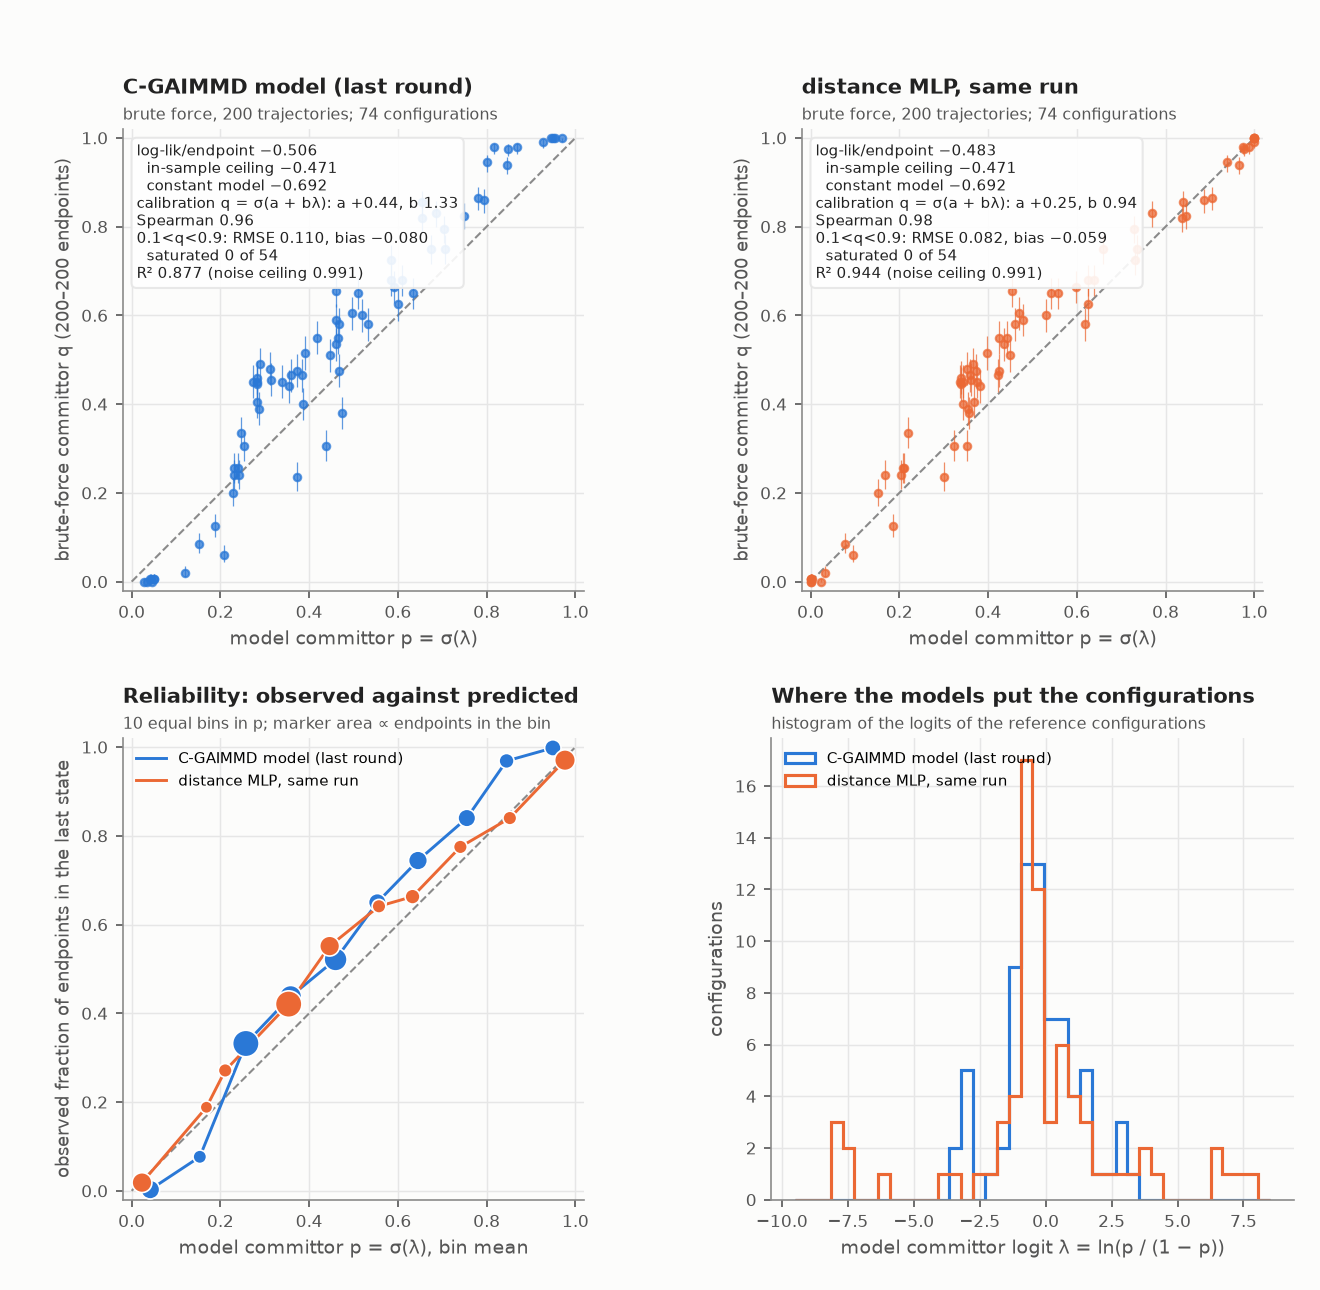

In [17]:
from IPython.display import Image, display

models = {"C-GAIMMD model (last round)": validate.network_committor(network),
          "distance MLP, same run": validate.network_committor(baseline)}
scores = {name: validate.score_committor(committor, reference)
          for name, committor in models.items()}
print(f"{'':28s} {'log-lik/endpoint':>16s} {'calibration slope':>18s} {'Spearman':>9s} "
      f"{'R2':>6s} {'R2 noise ceiling':>17s}")
for name, (report, _) in scores.items():
    print(f"{name:28s} {report['loglik_per_endpoint']:16.3f} {report['calibration_slope']:18.2f} "
          f"{report['spearman']:9.2f} {report['r2']:6.2f} {report['r2_noise_ceiling']:17.2f}")
print(f"constant model {report['loglik_constant']:.3f}, exact committor (estimated ceiling) "
      f"{report['loglik_true_committor_estimate']:.3f} per endpoint")

png, pdf = validate.parity_figure([(name, reference, logits)
                                   for name, (_, logits) in scores.items()],
                                  os.path.join(ANALYSIS, "committor_parity"))
display(Image(png, width=760))

## 7. How closely the generator follows the requested committor

The generator is asked for configurations at a requested committor
$\lambda^*$; how good it is as a *dial* is measured by *judging* its samples:
giving each a committor $\lambda$ with some model and comparing with the
request. Here 64 raw samples are drawn at each of nine requests from −4 to 4
with the run's last network (`draw_samples`, through the same generation
interface the shooting workers use), prepared as the run would prepare them
(the sites put back), and judged three ways:

- by the generator's **own committor**, which is what the run's final check
  sees: a generator can follow its own committor and still miss the true one;
- by the **distance MLP** of section 6, a model that shares no weights with the
  generator: an independent judge, as one uses for a molecule;
- for the toy, by **brute force**: 64 trajectories from every sample.

`adherence_metrics` turns the pairs $(\lambda^*, \lambda)$ into numbers:

- **slope** of the least-squares line $\lambda = a + b\lambda^*$: 1 for a
  perfect dial, 0 for a generator that ignores the request;
- **resolution**: the robust spread of $\lambda$ around that line divided by
  the slope, in logits: how far apart two requests must be before their samples
  can be told apart (smaller is better);
- **median slopes** over the *core* ($|\lambda^*| \le 1$), the *band*
  ($|\lambda^*| \le 2$, the transition region) and the *wings*
  ($|\lambda^*| > 2$): a steep slope over the band can hide a flat core, where
  the samples only jump between the two sides;
- **large misses**: the share of samples judged more than 3 logits from their
  request.

In [18]:
from aimmd.cgaimmd.analysis import adherence

LEVELS = [-4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0]
samples = validate.draw_samples(network, LEVELS, 64, seed=0)
requested = np.repeat(samples.levels, samples.positions.shape[1])
raw = samples.positions.reshape(-1, 3, 3)
prepared = np.array([params.cgaimmd_prepare_function(sample, None).positions for sample in raw])

judges = {"own committor": validate.network_committor(network)(prepared),
          "distance MLP": validate.network_committor(baseline)(prepared)}
n_a, n_b = three_hole.shoot_one_way(prepared[:, 0, 0], prepared[:, 0, 1], 64, rng)
q = (n_b + 0.5) / (n_a + n_b + 1)                 # +0.5 and +1: no infinite logit at 0 or 64 of 64
judges["brute force, 64 trajectories"] = np.log(q / (1 - q))

print(f"{'judge':30s} {'slope':>6s} {'resolution':>11s} {'core slope':>11s} {'band slope':>11s} "
      f"{'large misses':>13s}")
for name, judged in judges.items():
    m = adherence.adherence_metrics(requested, judged, n_boot=100)
    large = np.mean(np.abs(judged - requested) > adherence.LARGE_MISS)
    print(f"{name:30s} {m['all_requests']['slope']:6.2f} {m['all_requests']['resolution']:11.2f} "
          f"{m['median_slopes']['core']['slope']:11.2f} {m['median_slopes']['band']['slope']:11.2f} "
          f"{large:13.2f}")

judge                           slope  resolution  core slope  band slope  large misses


own committor                    0.75        1.57        1.07        0.97          0.02


distance MLP                     1.68        1.70        1.83        2.02          0.39


brute force, 64 trajectories     1.17        1.71        1.98        1.79          0.10


How to read the three rows: the judges disagree because each has its own
errors. A judge whose committor is steeper than the labels the generator was
trained on (the run's own committor) makes every slope steeper; a noisy judge
makes every resolution worse. Brute force has neither problem, but only the
toy can afford it for hundreds of samples. So every number is read against the
*data ceiling* of the same judge (`data_ceiling`): frames of the generator's
training data drawn at their own committor label and judged alike. A generator
that reproduced its training data perfectly would score about this.

In [19]:
shot_frames = np.flatnonzero(table.is_shot & (table.state == "R"))
ceiling = adherence.data_ceiling(table.value[shot_frames], LEVELS, n_per_level=64, seed=0)
frames = np.zeros((len(ceiling["indices"]), 3, 3))
frames[:, 0, :2] = table.cv[shot_frames[ceiling["indices"]]]
frames[:, 1:] = three_hole.SITES
m = adherence.adherence_metrics(ceiling["requested"],
                                validate.network_committor(baseline)(frames), n_boot=0)
print(f"data ceiling, judged by the distance MLP: slope {m['all_requests']['slope']:.2f}, "
      f"resolution {m['all_requests']['resolution']:.2f}")

data ceiling, judged by the distance MLP: slope 2.02, resolution 0.46


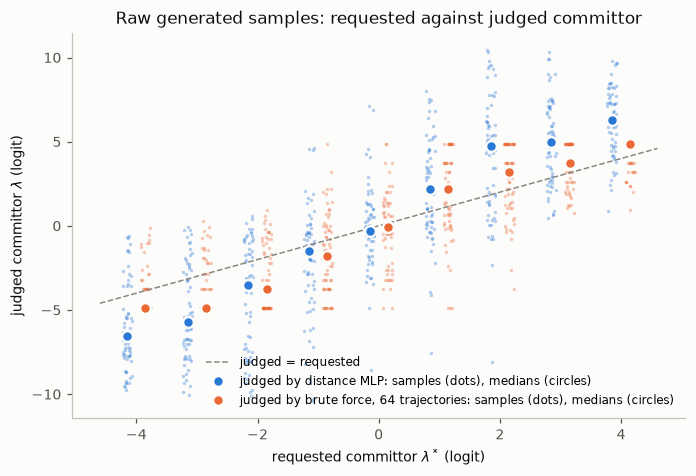

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.plot([-4.6, 4.6], [-4.6, 4.6], color=MUTED, linewidth=1, linestyle="--",
        label="judged = requested")
for name, color, offset in (("distance MLP", BLUE, -0.15),
                            ("brute force, 64 trajectories", ORANGE, 0.15)):
    judged = judges[name]
    jitter = rng.uniform(-0.08, 0.08, len(requested))
    ax.scatter(requested + offset + jitter, judged, s=5, color=color, alpha=0.35, linewidth=0)
    medians = [np.median(judged[requested == level]) for level in LEVELS]
    ax.plot(np.array(LEVELS) + offset, medians, "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5,
            label=f"judged by {name}: samples (dots), medians (circles)")
ax.set_xlabel(r"requested committor $\lambda^*$ (logit)")
ax.set_ylabel(r"judged committor $\lambda$ (logit)")
ax.legend(loc="lower right")
ax.set_title("Raw generated samples: requested against judged committor")
fig.tight_layout()
plt.show()

**Do the samples look like MD at their committor?** Structures are compared
through *features*; here the features are $x$ and $y$ of the particle, for a
molecule the distances between its heavy atoms
(`adherence.pair_distance_features`). The yardstick is a set of independent MD
frames binned by their committor label, $\pm 0.5$ around each request
(`label_binned_reference`). For the toy, these are fresh trajectories started
from equilibrium frames of the run, labelled by the run's last network.
`sample_quality` reports:

- **variety ratio**: the median distance between two samples of one request,
  divided by the same for the MD frames at that committor. About 1: as varied
  as MD; well below 1: the generator collapses onto a few structures.
- **departure ratio**: the median distance of the samples to their nearest
  training frame, divided by the same for the MD frames. About 1: the samples
  stay where MD goes; well above 1: they leave it.
- **near-copies**: the share of samples closer to a training frame than two
  consecutive MD frames are to each other (`consecutive_frame_threshold`).
  Compare it with the same share for the MD frames: in two dimensions the
  run's frames cover the plane so densely that every configuration is a
  near-copy; for a molecule, with hundreds of coordinates, the share separates
  a generator that recalls its training frames from one that makes new ones.

Read the departure ratio next to the shooting-point figure of section 4: a
request whose samples sit where equilibrium MD rarely goes, such as the hill
between the two channels, has a departure ratio well above 1.

In [21]:
def features(positions):
    """The structural description used here: x and y of the particle."""
    return np.asarray(positions)[:, 0, :2]


starts = table.cv[rng.choice(np.flatnonzero(~table.is_shot), 200, replace=False)]
fresh = three_hole.trajectories(starts[:, 0], starts[:, 1], 300, rng)      # (300, 200, 2)
fresh_frames = np.zeros((fresh.shape[0] * fresh.shape[1], 3, 3))
fresh_frames[:, 0, :2] = fresh.reshape(-1, 2)
fresh_frames[:, 1:] = three_hole.SITES
in_r = three_hole.state_of(fresh_frames[:, 0, 0], fresh_frames[:, 0, 1]) == "R"
md_labels = validate.network_committor(network)(fresh_frames[in_r])
near_copy = adherence.consecutive_frame_threshold(fresh[:-1].reshape(-1, 2),
                                                  fresh[1:].reshape(-1, 2))
training = table.cv                                    # x, y of every frame of the run

md_reference = adherence.label_binned_reference(md_labels, features(fresh_frames[in_r]), LEVELS,
                                                training_features=training,
                                                near_copy_threshold=near_copy)
quality = adherence.sample_quality(requested, features(prepared), md_reference,
                                   training_features=training, near_copy_threshold=near_copy)
print(f"near-copy line (median distance between consecutive MD frames): {near_copy:.3f} Å")
print(f"{'request':>8s} {'variety ratio':>14s} {'departure ratio':>16s} {'near-copies':>12s} "
      f"{'near-copies of MD':>18s}")
for level, entry in quality["per_request"].items():
    md_share = md_reference[level].get("near_copy_share")
    print(f"{level:8.1f} {entry['variety_ratio'] or float('nan'):14.2f} "
          f"{entry['departure_ratio'] or float('nan'):16.2f} {entry['near_copy_share']:12.2f} "
          f"{md_share if md_share is not None else float('nan'):18.2f}")

near-copy line (median distance between consecutive MD frames): 0.171 Å
 request  variety ratio  departure ratio  near-copies  near-copies of MD
    -4.0           2.46             1.17         1.00               1.00
    -3.0           1.33             1.39         0.98               1.00
    -2.0           1.58             0.91         1.00               1.00
    -1.0           1.29             1.17         1.00               1.00
     0.0           1.51             1.08         1.00               1.00
     1.0           1.11             0.68         1.00               1.00
     2.0           1.48             1.19         1.00               1.00
     3.0           1.82             1.91         0.97               1.00
     4.0           4.21             0.68         1.00               1.00


## 8. Shooting validation of generated configurations

The final test of a generator is to shoot from its samples: the share of
trajectories that end in B is the committor the samples really have. This
needs no committor model at all.

**The run's own shots** are one two-way shot per generated configuration, so
they are a shooting validation that costs nothing. `from_shot_table` turns
them into samples grouped by request (bins of width 1 around the integers),
and `level_summary` gives each request's measured committor (the share of
halves that ended in B) with a bootstrap interval. These samples passed the
final check, which accepted a candidate only if the run's network put it
within 1 of its request: they measure the generator and the check together.

In [22]:
from aimmd.cgaimmd.analysis import shooting_validation

own = shooting_validation.from_shot_table(rows, states=params.sorted_states)
checked = [sample for sample in own if sample["acceptance_enforced"]]
own_levels = shooting_validation.level_summary(checked, n_boot=500)
print(f"{len(own)} shots, {len(checked)} of them under the final check")
for entry in own_levels:
    print(f"request {entry['level']:+.0f}: {entry['n_shot']:3d} shots, measured committor "
          f"{entry['committor_mean']:.2f} {np.round(entry['committor_mean_interval'], 2)}, "
          f"requested {entry['requested_committor']:.2f}")

184 shots, 116 of them under the final check


request -3:  11 shots, measured committor 0.00 [0. 0.], requested 0.05
request -2:  21 shots, measured committor 0.05 [0.   0.12], requested 0.12
request -1:  26 shots, measured committor 0.29 [0.17 0.42], requested 0.27
request +0:  14 shots, measured committor 0.46 [0.25 0.68], requested 0.50
request +1:  13 shots, measured committor 0.81 [0.62 0.96], requested 0.73
request +2:  27 shots, measured committor 0.93 [0.85 0.98], requested 0.88
request +3:   4 shots, measured committor 1.00 [1. 1.], requested 0.95


**Fresh samples** measure the generator alone. `write_validation_frames`
draws samples at the requests with the run's generator, prepares each with the
run's own hooks and checks its state (the committor part of the final check is
left out), and writes the frames to shoot and a manifest into a folder you
name. An AIMMD sweep then shoots every frame once: a plain `rfps` params file
whose initial path is the frames file, run with
`reactive_region_mode='sweep'`. `sweep_outcomes` reads which shot came from
which frame, `validation_rows` joins them with the manifest, and
`level_summary` and `dial_slope` summarise.

Some samples cannot be shot: a sample whose prepared frame lies in A or B
counts as a shot with both halves there (it is listed as
`first_state_at_time_zero` or `last_state_at_time_zero`), and a sample the
validity check or the preparation refused (`failed_<reason>`) has no outcome.
When the sweep's params are loaded, AIMMD notes that their initial path has no
transition; for a sweep that is expected.

The **dial slope** is the slope $b$ of a logistic fit of every half's outcome
on the request, $P(\text{half ends in B}) = \sigma(a + b\lambda^*)$: 1 for a
generator that delivers the committor it is asked for, 0 for one that ignores
the request.

In [23]:
import math

VALIDATION_LEVELS = [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0]
FRAMES_DIR = os.path.join(ANALYSIS, "validation_frames")
manifest = shooting_validation.write_validation_frames(params, FRAMES_DIR, VALIDATION_LEVELS, 8,
                                                       run_dir=RUN, seed=1)
n_frames = manifest["meta"]["n_frames"]
classes = {}
for sample in manifest["samples"]:
    classes[sample["outcome_class"]] = classes.get(sample["outcome_class"], 0) + 1
print(f"{len(manifest['samples'])} samples {classes}: {n_frames} frames to shoot")

SWEEP_PARAMS = '''
"""A committor sweep of the validation frames: the toy's dynamics and states, plain two-way shots."""
from three_hole import ParticleNetwork, states_function, toy_mdrun

engine = 'toy'
toy_slowdown = 0.0005
states = 'ARB'
chain_type = 'rfps'
initial_paths = ['analysis/validation_frames/shooting_frames.xtc']
round_shooting_index = True


class Network(ParticleNetwork):      # a sweep does not use it, but its workers load a network
    pass


network = Network()
'''
with open("params_sweep.py", "w") as handle:
    handle.write(SWEEP_PARAMS.lstrip())
SWEEP = ("import aimmd; aimmd.Launcher('params_sweep.py', 'validation_sweep')"
         f".run(4, reactive_region_mode='sweep', nsteps={math.ceil(n_frames / 4)})")
with open("sweep.log", "w") as log:
    subprocess.run([sys.executable, "-c", SWEEP], stdout=log, stderr=subprocess.STDOUT, check=True)

sweep_params = aimmd.Params.load("params_sweep.py", save=False)
sweep = shooting_validation.sweep_outcomes("validation_sweep", n_frames, params=sweep_params,
                                           frames=os.path.join(FRAMES_DIR, "shooting_frames.xtc"))
validation = shooting_validation.validation_rows(manifest, sweep)
fresh_levels = shooting_validation.level_summary(validation, n_boot=500)
dial = shooting_validation.dial_slope(validation, n_boot=500)
for entry in fresh_levels:
    print(f"request {entry['level']:+.0f}: {entry['n_shot']} frames shot, measured committor "
          f"{entry['committor_mean']:.2f} {np.round(entry['committor_mean_interval'], 2)}, "
          f"requested {entry['requested_committor']:.2f}")
print(f"dial slope {dial['slope']:.2f}, 95 % interval {np.round(dial['slope_interval'], 2)}, "
      f"from {dial['n_committed_halves']} halves")

56 samples {'shoot': 43, 'first_state_at_time_zero': 4, 'failed_outside_region': 1, 'last_state_at_time_zero': 8}: 43 frames to shoot


Perhaps you are using it for brute-force shooting?


request -3: 5 frames shot, measured committor 0.06 [0.   0.19], requested 0.05
request -2: 6 frames shot, measured committor 0.07 [0.   0.21], requested 0.12
request -1: 8 frames shot, measured committor 0.12 [0.   0.25], requested 0.27
request +0: 8 frames shot, measured committor 0.62 [0.25 0.88], requested 0.50
request +1: 7 frames shot, measured committor 0.62 [0.25 1.  ], requested 0.73
request +2: 7 frames shot, measured committor 1.00 [1. 1.], requested 0.88
request +3: 2 frames shot, measured committor 0.88 [0.62 1.  ], requested 0.95
dial slope 1.05, 95 % interval [0.7  1.78], from 110 halves


**Requested against measured committor**, the inset of the shooting-point
figure: the ideal line and, per request, the measured committor with its 95 %
interval. With one shot per sample and eight samples per request the intervals
are wide; a validation campaign shoots more samples per request.

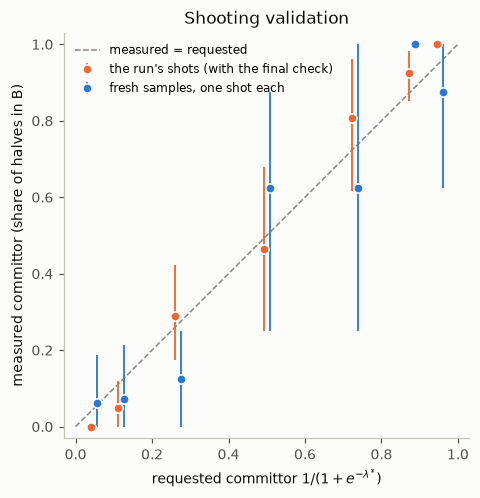

In [24]:
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="measured = requested")
for entries, color, label, offset in (
        (own_levels, ORANGE, "the run's shots (with the final check)", -0.008),
        (fresh_levels, BLUE, "fresh samples, one shot each", 0.008)):
    entries = [e for e in entries if e["committor_mean"] is not None
               and np.isfinite(e["committor_mean"])]
    x = np.array([e["requested_committor"] for e in entries]) + offset
    y = np.array([e["committor_mean"] for e in entries])
    low, high = np.array([e["committor_mean_interval"] for e in entries]).T
    ax.errorbar(x, y, yerr=[y - low, high - y], fmt="o", color=color, markersize=6,
                markeredgecolor=SURFACE, elinewidth=1.2, capsize=0, label=label)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_aspect("equal")
ax.set_xlabel(r"requested committor $1/(1 + e^{-\lambda^*})$")
ax.set_ylabel("measured committor (share of halves in B)")
ax.legend(loc="upper left")
ax.set_title("Shooting validation")
fig.tight_layout()
plt.show()

## 9. The run card

`run_card` collects every setting of a run in one JSON-ready dictionary: every
params field and the ones that differ from the defaults, the engine, the
network (class, size, architecture, the digest of its file), the fit and the
keywords of its last round, the C-GAIMMD settings with their defaults filled
in, the generator, the hooks, the bias, and the versions of AIMMD and of the
software around it. `run_card_rows` flattens it into (section, setting, value)
rows, with LaTeX escaping on request, for the tables of a supplement.

In [25]:
from aimmd.analysis.run_card import run_card, run_card_rows

card = run_card(params, RUN)
with open(os.path.join(ANALYSIS, "run_card.json"), "w") as handle:
    json.dump(card, handle, indent=1)
every_row = run_card_rows(card, skip_none=True)
print(f"{len(every_row)} settings in {len(card)} sections, among them:")
for section, setting, value in every_row:
    if setting.startswith(("settings.lambda", "settings.acceptance", "settings.window",
                           "generator.settings", "last_round.keywords")):
        print(f"  {section:8s} {setting:37s} {value}")

with open(os.path.join(ANALYSIS, "run_card.tex"), "w") as handle:
    for row in run_card_rows(card, sections=["cgaimmd", "fit"], latex=True, skip_none=True):
        handle.write(" & ".join(row) + r" \\" + "\n")
print("\nin", short(ANALYSIS) + ":", sorted(os.listdir(ANALYSIS)))

202 settings in 17 sections, among them:
  fit      last_round.keywords.ema_decay         0.99
  fit      last_round.keywords.lr                0.003
  fit      last_round.keywords.relabel_every     500
  fit      last_round.keywords.steps_per_round   1500
  fit      last_round.keywords.warmup_steps      0
  cgaimmd  settings.lambda_law                   uniform
  cgaimmd  settings.lambda_window                [-3.0, 3.0]
  cgaimmd  settings.acceptance                   target
  cgaimmd  settings.lambda_tolerance             1
  cgaimmd  settings.window_after_trained_shots   30
  cgaimmd  generator.settings.sampler            midpoint
  cgaimmd  generator.settings.n_steps            16
  cgaimmd  generator.settings.chunk              64
  cgaimmd  generator.settings.guidance_scale     1

in analysis: ['committor_parity.pdf', 'committor_parity.png', 'distance_mlp.pt', 'rates.json', 'rates.npz', 'run_card.json', 'run_card.tex', 'validation_frames']


## 10. Where to go from here

- **Analysis and estimators** (documentation page): which rate estimators are
  valid for C-GAIMMD runs and why, what a static bias changes, and a list of
  every analysis of this tutorial with the functions that make it.
- **The API pages** of `aimmd.analysis.reweighting`, `aimmd.analysis.free_md`,
  `aimmd.analysis.run_card` and `aimmd.cgaimmd.analysis` define every number in
  their docstrings; `validate.validate` runs the whole committor and generator
  protocol for one network and writes a report and a model card.
- **References for a molecular system**: `validate.sweep_reference` reads the
  brute-force committor of an AIMMD sweep; `validate.heldout_chain_reference`
  turns the shots of chains the trainer held out into a reference;
  `aimmd.analysis.free_md.free_md_reference` scores a network on the
  outcomes of the run's own free simulations.
- **Tutorials 4 to 6** run C-GAIMMD on alanine dipeptide, chignolin and
  trypsin with benzamidine; every analysis here applies to their run folders.